Figure 2: cross-shelf bore statistics


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Run with current directory as the working directory. Make sure djl_stats.npz and bore_stats.npz are in this directory.
data_dir = Path('.')
djl_file = data_dir / 'djl_stats.npz'

def load_stats(path, keys, expected_shape=None):
    with np.load(path, allow_pickle=False) as data:
        stats = {key: data[key] for key in keys}
    shape = next(iter(stats.values())).shape
    if len(shape) != 2 or any(value.shape != shape for value in stats.values()):
        raise ValueError(f'{path}: expected matching mooring x bore arrays')
    if expected_shape is not None and shape != expected_shape:
        raise ValueError(f'{path}: expected shape {expected_shape}, got {shape}')
    return stats

bore = load_stats(data_dir / 'bore_stats.npz',
                  ('H', 'S', 'U', 'etaB', 'etaGC', 'max_depression'))
djl = load_stats(djl_file, ('c0', 'alpha', 'cDJL', 'etaDJL', 'max_gradient'),
                 expected_shape=bore['H'].shape)
print(f"Loaded bore grid: {bore['H'].shape}")

# The combined archive may be a checkpoint from a still-running batch job.
with np.load(djl_file, allow_pickle=False) as data:
    if 'processed' in data:
        pending = np.isfinite(bore['H']) & ~data['processed']
        if np.any(pending):
            print(f'WARNING: {np.count_nonzero(pending)} saved bore arrivals have not been processed; '
                  'figure counts may be incomplete.')


Loaded bore grid: (42, 164)


Classification


In [2]:
H = bore['H']
S = bore['S']
U_B = bore['U']
c0 = djl['c0']
cDJL = djl['cDJL'].copy()
etaDJL = djl['etaDJL'] / H  
eta_observed = bore['max_depression'] / H

Delta_GC = np.full(H.shape, np.nan)
valid_index = np.isfinite(bore['etaB']) & np.isfinite(bore['etaGC']) & np.isfinite(S)
positive = valid_index & (bore['etaB'] > 0) & (S > 0)
Delta_GC[positive] = ((bore['etaGC'][positive] / bore['etaB'][positive])**2
                      * (1-S[positive]) / S[positive])
Delta_GC[valid_index & ~positive] = 0.0

deltastar = 0.1
condition0 = np.isfinite(H) & (U_B > 0.0*c0)
has_djl = cDJL > -1  
print('# mode-1 onshore propagating:', np.count_nonzero(condition0))
print('# existing DJL solutions:', np.count_nonzero(has_djl))

missing_djl_gc = condition0 & ~has_djl & (Delta_GC > deltastar)
print('# GCs without DJL solutions (use c0):', np.count_nonzero(missing_djl_gc))
cDJL[missing_djl_gc] = c0[missing_djl_gc]
etaDJL[missing_djl_gc] = 0.0

# 75% amplitude criterion 
test_cond = ((0.75*etaDJL < eta_observed))
condition = condition0 & ((cDJL > -1) | (Delta_GC > deltastar))
condition2 = condition & (Delta_GC > deltastar)       # GCs
condition3 = condition & ~condition2 & test_cond      # ASIBs
condition4 = condition & ~condition2 & ~test_cond     # UIBs
unclassified = condition0 & ~condition

print('# DJL solution exists or GC index > 0.1:', np.count_nonzero(condition))
print('# GCs:', np.count_nonzero(condition2))
print('# ASIBs:', np.count_nonzero(condition3))
print('# UIBs:', np.count_nonzero(condition4))
print('# unclassified:', np.count_nonzero(unclassified))
print('# ASIBs + GCs:', np.count_nonzero(condition3 | condition2))
assert np.count_nonzero(condition2 | condition3 | condition4 | unclassified) == np.count_nonzero(condition0)


# mode-1 onshore propagating: 1762
# existing DJL solutions: 1614
# GCs without DJL solutions (use c0): 54
# DJL solution exists or GC index > 0.1: 1640
# GCs: 199
# ASIBs: 1234
# UIBs: 207
# unclassified: 122
# ASIBs + GCs: 1433


In [3]:
bin_edges = np.array([0, 15, 30, 45, 60, 105])
bin_labels = ['9–15m', '20–30m', '32–40m', '50m', '100m']
x = np.arange(1, len(bin_edges))
bin_masks = [condition0 & (H >= low) & (H < high)
             for low, high in zip(bin_edges[:-1], bin_edges[1:])]
counts = np.array([np.count_nonzero(mask) for mask in bin_masks])

fractions = {}
for name, mask in [('ASIB', condition3), ('UIB', condition4), ('GC', condition2)]:
    numerator = np.array([np.count_nonzero(mask & depth_mask) for depth_mask in bin_masks])
    fractions[name] = np.divide(100.0*numerator, counts,
                                out=np.zeros(len(counts)), where=counts > 0)

def binned(values):
    return [values[mask & np.isfinite(values)] for mask in bin_masks]

etaB_binned = binned(bore['etaB'])
etaGC_binned = binned(bore['etaGC'])
excess_binned = binned(1-S)
delta_binned = binned(Delta_GC)
for label, mask, count in zip(bin_labels, bin_masks, counts):
    print(f'{label}: N={count}, ASIB={np.count_nonzero(mask & condition3)}, '
          f'UIB={np.count_nonzero(mask & condition4)}, GC={np.count_nonzero(mask & condition2)}')
print('# mode-1 arrivals outside original depth bins:',
      np.count_nonzero(condition0) - counts.sum())


9–15m: N=224, ASIB=142, UIB=9, GC=45
20–30m: N=538, ASIB=355, UIB=56, GC=84
32–40m: N=449, ASIB=331, UIB=42, GC=53
50m: N=486, ASIB=383, UIB=58, GC=17
100m: N=65, ASIB=23, UIB=42, GC=0
# mode-1 arrivals outside original depth bins: 0


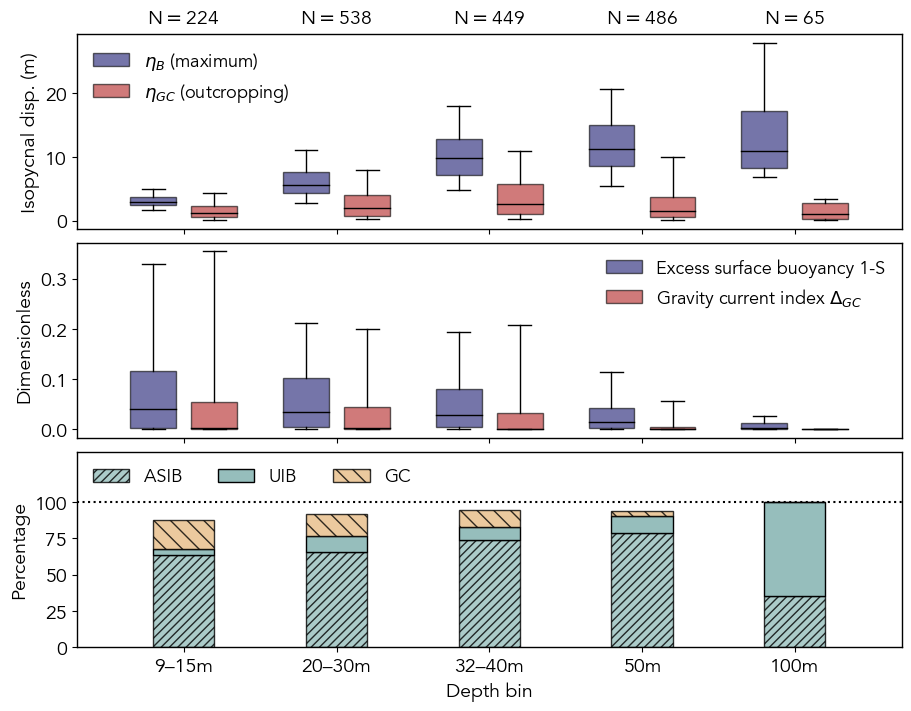

In [4]:
plt.rcParams.update({
    'figure.figsize': (9, 7), 'axes.facecolor': 'white', 'axes.grid': False,
    'font.family': 'sans-serif', 'font.sans-serif': ['Avenir', 'Avenir Next', 'Arial', 'DejaVu Sans'],
    'font.size': 14, 'text.usetex': False, 'axes.linewidth': 1.0,
})
fig, (ax_a, ax_b, ax_c) = plt.subplots(3, 1, sharex=True, constrained_layout=True)
fig.patch.set_alpha(0.0)

def paired_boxes(ax, left, right, labels, legend_location):
    common = dict(widths=0.3, patch_artist=True, medianprops={'color': 'black'},
                  whis=(5, 95), showfliers=False)
    b1 = ax.boxplot(left, positions=x-0.2,
                    boxprops={'facecolor': 'midnightblue', 'alpha': 0.6}, **common)
    b2 = ax.boxplot(right, positions=x+0.2,
                    boxprops={'facecolor': 'firebrick', 'alpha': 0.6}, **common)
    ax.legend([b1['boxes'][0], b2['boxes'][0]], labels,
              loc=legend_location, frameon=False, fontsize=13)

paired_boxes(ax_a, etaB_binned, etaGC_binned,
             [r'$\eta_B$ (maximum)', r'$\eta_{GC}$ (outcropping)'], 'upper left')
ax_a.set_ylabel('Isopycnal disp. (m)')
for position, count in zip(x, counts):
    ax_a.annotate(f'N$=${count}', (position, 31), annotation_clip=False, ha='center')

paired_boxes(ax_b, excess_binned, delta_binned,
             [r'Excess surface buoyancy 1-S', r'Gravity current index $\Delta_{GC}$'],
             'upper right')
ax_b.set_ylabel('Dimensionless')

f_asib, f_uib, f_gc = (fractions[key] for key in ('ASIB', 'UIB', 'GC'))
ax_c.bar(x, f_asib, 0.4, color='#96bebc', edgecolor='black', hatch='////', alpha=0.8, label='ASIB')
ax_c.bar(x, f_uib, 0.4, bottom=f_asib, color='#96bebc', edgecolor='black', label='UIB')
ax_c.bar(x, f_gc, 0.4, bottom=f_asib+f_uib, color='#e7bc86', edgecolor='black',
         hatch='\\\\', alpha=0.8, label='GC')
ax_c.set_ylim(0, 135)
ax_c.set_yticks(np.linspace(0, 100, 5))
ax_c.axhline(100, linestyle='dotted', color='black')
ax_c.legend(loc='upper left', frameon=False, fontsize=13, ncols=3)
ax_c.set_ylabel('Percentage')
ax_c.set_xlabel('Depth bin')
ax_c.set_xticks(x, bin_labels)
# for ax, label in zip((ax_a, ax_b, ax_c), ('a)', 'b)', 'c)')):
#     ax.patch.set_alpha(0.0)
#     ax.text(-0.06, 1.05, label, transform=ax.transAxes,
#             fontsize=16, va='bottom', ha='right', fontweight='bold')

fig.savefig(data_dir / 'fig2_noannotation.pdf', dpi=300, bbox_inches='tight', transparent=True)
fig.savefig(data_dir / 'fig2_noannotation.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


In [5]:
# Inshore of 50 m: same denominator population as Figure 2, including unclassified arrivals.
inshore = condition0 & (H < 43)
n_inshore = np.count_nonzero(inshore)
print(f'Mode-1 onshore arrivals inshore of 50 m: N={n_inshore}')
for name, mask in [('ASIBs', condition3), ('UIBs', condition4), ('GCs', condition2),
                   ('ASIBs + GCs', condition3 | condition2)]:
    count = np.count_nonzero(inshore & mask)
    percentage = 100*count/n_inshore if n_inshore else np.nan
    print(f'{name}: {count}/{n_inshore} = {percentage:.1f}%')


Mode-1 onshore arrivals inshore of 50 m: N=1211
ASIBs: 828/1211 = 68.4%
UIBs: 107/1211 = 8.8%
GCs: 182/1211 = 15.0%
ASIBs + GCs: 1010/1211 = 83.4%


In [6]:
# Ratio of medians (not median of individual ratios), using the Figure 2 boxplot samples.
amplitude_ratio_stats = {}
for label, etaB_values, etaGC_values in zip(bin_labels, etaB_binned, etaGC_binned):
    median_etaB = np.median(etaB_values) if len(etaB_values) else np.nan
    median_etaGC = np.median(etaGC_values) if len(etaGC_values) else np.nan
    ratio_of_medians = median_etaGC/median_etaB if median_etaB > 0 else np.nan
    amplitude_ratio_stats[label] = {
        'median_etaB': median_etaB,
        'median_etaGC': median_etaGC,
        'ratio_of_medians': ratio_of_medians,
    }
    print(f'{label}: median etaB={median_etaB:.3f} m, '
          f'median etaGC={median_etaGC:.3f} m, '
          f'median(etaGC)/median(etaB)={ratio_of_medians:.4f}')


9–15m: median etaB=2.978 m, median etaGC=1.143 m, median(etaGC)/median(etaB)=0.3839
20–30m: median etaB=5.637 m, median etaGC=2.046 m, median(etaGC)/median(etaB)=0.3629
32–40m: median etaB=9.818 m, median etaGC=2.540 m, median(etaGC)/median(etaB)=0.2587
50m: median etaB=11.250 m, median etaGC=1.455 m, median(etaGC)/median(etaB)=0.1293
100m: median etaB=10.947 m, median etaGC=1.026 m, median(etaGC)/median(etaB)=0.0937


In [11]:
#Convert to MATLAB
from scipy.io import savemat

# Numeric arrays only; preserves the mooring × bore layout.
# Note dates and mooring numbers not saved
savemat('bore_stats.mat', {
    key: value for key, value in bore.items()
    if key not in ('datetime', 'mooring')
})

with np.load('djl_stats.npz') as data:
    savemat('djl_stats.mat', {key: data[key] for key in data.files})